In [1]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

main_dir = '/home/gap2/Downloads/PPRL-Dev-main/results/clustering/D2/'

In [2]:
df_cosine = pd.read_csv(main_dir + 'KiralyMSMApproximateClustering_cosine.csv')
df_cosine['similarity'] = 'cosine'
df_dice = pd.read_csv(main_dir + 'KiralyMSMApproximateClustering_dice.csv')
df_dice['similarity'] = 'dice'
df_jaccard = pd.read_csv(main_dir + 'KiralyMSMApproximateClustering_jaccard.csv')
df_jaccard['similarity'] = 'jaccard'
df_scm = pd.read_csv(main_dir + 'KiralyMSMApproximateClustering_scm.csv')
df_scm['similarity'] = 'scm'

In [3]:
result = pd.DataFrame()
dfs = [df_cosine, df_dice, df_jaccard, df_scm]
for df in dfs:
    result = pd.concat([result, df], ignore_index=True, sort=False)

result['config_dict'] = result['config'].apply(ast.literal_eval)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,total_clusters,threshold,matcher,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,Clustering with KiralyMSMApproximateClustering,1305,0.20,cosine,95.33,74.81,83.83,796,39,808,268,cosine,[name],1024,0,1,salted_qgrams,,4
1,Clustering with KiralyMSMApproximateClustering,1306,0.30,cosine,95.32,74.72,83.77,795,39,807,269,cosine,[name],1024,0,1,salted_qgrams,,4
2,Clustering with KiralyMSMApproximateClustering,1311,0.40,cosine,95.42,74.34,83.57,791,38,803,273,cosine,[name],1024,0,1,salted_qgrams,,4
3,Clustering with KiralyMSMApproximateClustering,1305,0.10,cosine,95.33,74.81,83.83,796,39,808,268,cosine,[name],1024,0,1,salted_qgrams,,4
4,Clustering with KiralyMSMApproximateClustering,1351,0.50,cosine,95.44,70.77,81.27,753,36,765,311,cosine,[name],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2427,Clustering with KiralyMSMApproximateClustering,744,0.55,scm,89.11,62.31,73.34,663,81,675,401,scm,[name],1024,0,32,salted_qgrams,,4
2428,Clustering with KiralyMSMApproximateClustering,748,0.65,scm,89.57,62.97,73.95,670,78,682,394,scm,[name],1024,0,32,salted_qgrams,,4
2429,Clustering with KiralyMSMApproximateClustering,644,0.75,scm,91.30,55.26,68.85,588,56,600,476,scm,[name],1024,0,32,salted_qgrams,,4
2430,Clustering with KiralyMSMApproximateClustering,295,0.85,scm,96.61,26.79,41.94,285,10,297,779,scm,[name],1024,0,32,salted_qgrams,,4


In [4]:
result['attributes'].value_counts()

attributes
[name]    2432
Name: count, dtype: int64

In [5]:
result['offset'].value_counts()

offset
0    2432
Name: count, dtype: int64

In [6]:
result['hashing_type'].value_counts()

hashing_type
salted_qgrams    2432
Name: count, dtype: int64

In [7]:
result['qgrams'].value_counts()

qgrams
4    2432
Name: count, dtype: int64

In [8]:
result['size'].value_counts()

size
1024    2432
Name: count, dtype: int64

In [9]:
result['num_hashes'].value_counts()

num_hashes
1     76
2     76
3     76
4     76
5     76
6     76
7     76
8     76
9     76
10    76
11    76
12    76
13    76
14    76
15    76
16    76
17    76
18    76
19    76
20    76
21    76
22    76
23    76
24    76
25    76
26    76
27    76
28    76
29    76
30    76
31    76
32    76
Name: count, dtype: int64

In [10]:
max_f1 = result.loc[result.groupby(['num_hashes','similarity'])['F1 %'].idxmax()]
max_f1

,name,total_clusters,threshold,matcher,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,Clustering with KiralyMSMApproximateClustering,1305,0.2,cosine,95.33,74.81,83.83,796,39,808,268,cosine,[name],1024,0,1,salted_qgrams,,4
615,Clustering with KiralyMSMApproximateClustering,1309,0.2,dice,94.71,73.97,83.06,787,44,799,277,dice,[name],1024,0,1,salted_qgrams,,4
1216,Clustering with KiralyMSMApproximateClustering,1309,0.1,jaccard,94.71,73.97,83.06,787,44,799,277,jaccard,[name],1024,0,1,salted_qgrams,,4
1824,Clustering with KiralyMSMApproximateClustering,1347,0.5,scm,93.19,69.45,79.59,739,54,751,325,scm,[name],1024,0,1,salted_qgrams,,4
10,Clustering with KiralyMSMApproximateClustering,1300,0.2,cosine,94.88,74.91,83.72,797,43,809,267,cosine,[name],1024,0,2,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2096,Clustering with KiralyMSMApproximateClustering,1372,0.6,scm,89.45,64.57,75.00,687,81,699,377,scm,[name],1024,0,31,salted_qgrams,,4
282,Clustering with KiralyMSMApproximateClustering,1516,0.1,cosine,91.03,53.38,67.30,568,56,580,496,cosine,[name],1024,0,32,salted_qgrams,,4
890,Clustering with KiralyMSMApproximateClustering,1485,0.6,dice,90.08,55.45,68.64,590,65,602,474,dice,[name],1024,0,32,salted_qgrams,,4
1500,Clustering with KiralyMSMApproximateClustering,1485,0.4,jaccard,90.08,55.45,68.64,590,65,602,474,jaccard,[name],1024,0,32,salted_qgrams,,4


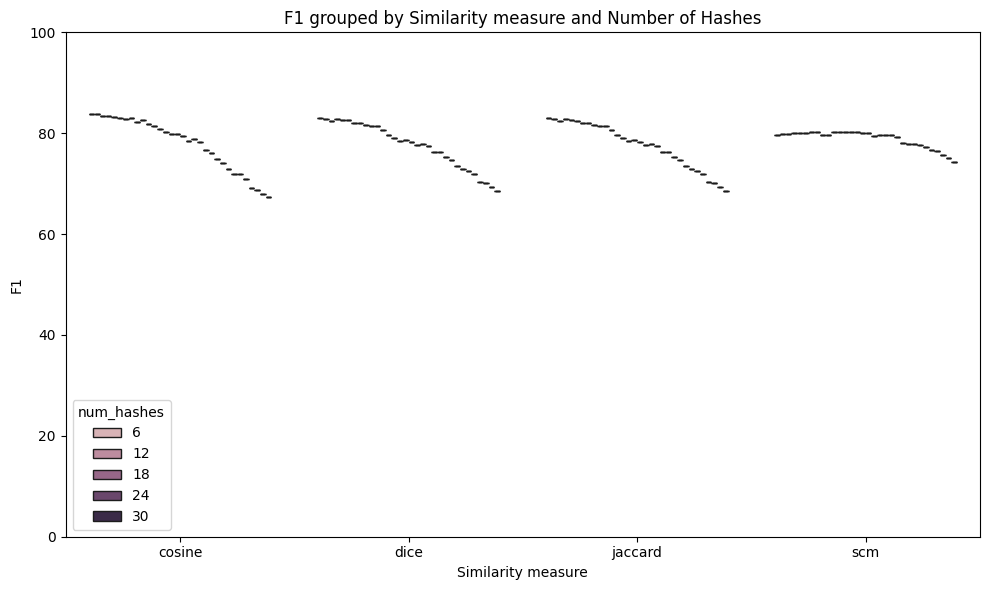

In [11]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=max_f1,
    x="similarity",
    y="F1 %",
    hue="num_hashes"
)

plt.title("F1 grouped by Similarity measure and Number of Hashes")
plt.xlabel("Similarity measure")
plt.ylabel("F1")
plt.ylim(0, 100) 
plt.legend(title="num_hashes")
plt.tight_layout()
plt.show()

In [12]:
metrics_df = max_f1.melt(
    id_vars=["similarity", "num_hashes"],
    value_vars=["Precision %", "Recall %", "F1 %"],
    var_name="Metric",
    value_name="Score"
)
metrics_df

,similarity,num_hashes,Metric,Score
0,cosine,1,Precision %,95.33
1,dice,1,Precision %,94.71
2,jaccard,1,Precision %,94.71
3,scm,1,Precision %,93.19
4,cosine,2,Precision %,94.88
...,...,...,...,...
379,scm,31,F1 %,75.00
380,cosine,32,F1 %,67.30
381,dice,32,F1 %,68.64
382,jaccard,32,F1 %,68.64


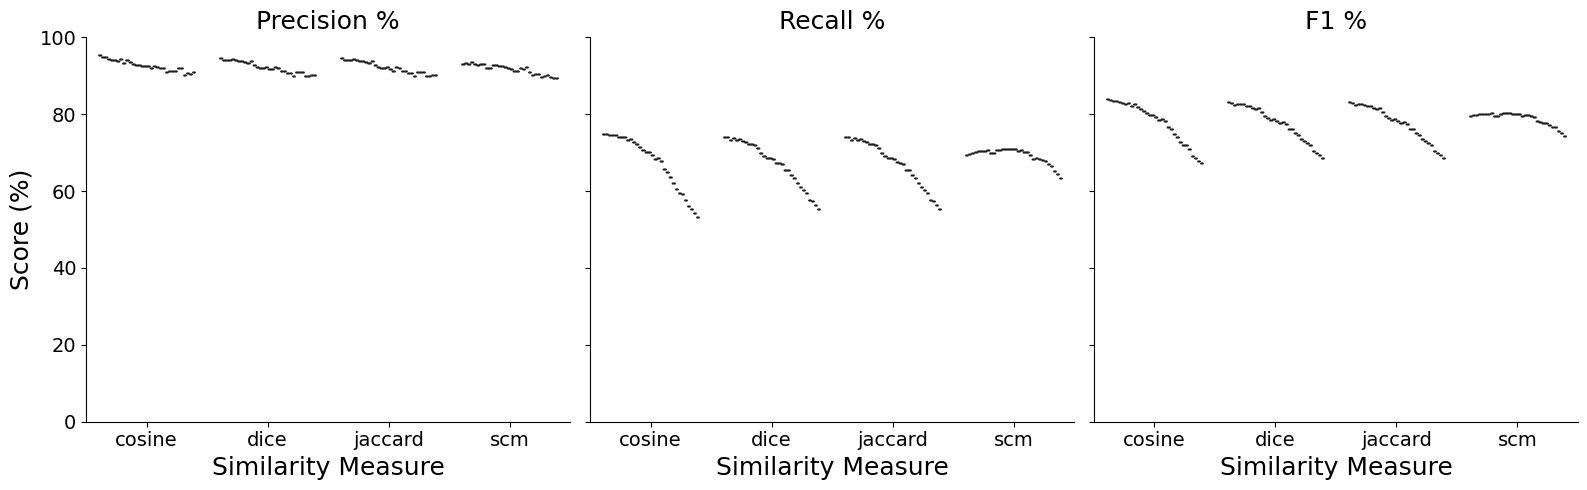

In [13]:
g = sns.catplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="num_hashes",
    col="Metric",
    kind="box",
    height=5,
    aspect=1,
    fliersize=14  # increase dot size
)
g._legend.remove()
g.set(ylim=(0, 100))
g.set_axis_labels("Similarity Measure", "Score (%)", fontsize=18)
g.set_titles("{col_name}", size=18)
for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

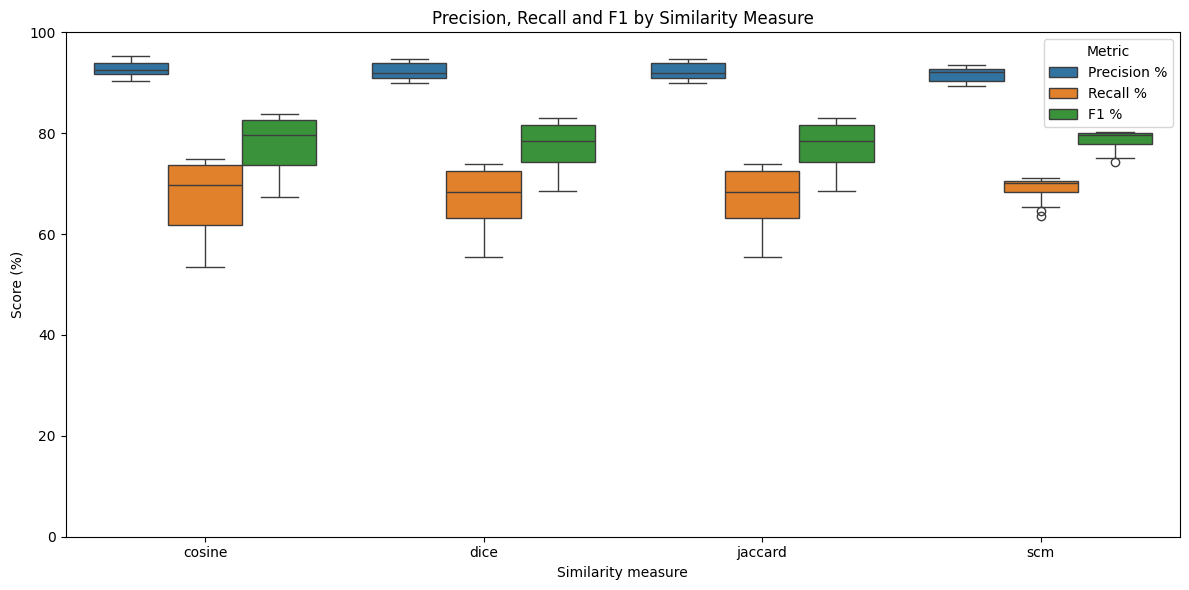

In [14]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 by Similarity Measure")
plt.xlabel("Similarity measure")
plt.ylabel("Score (%)")
plt.ylim(0, 100) 
plt.legend(title="Metric")
plt.tight_layout()
plt.show()